# Modelo 2: árbol de decisión

**Proyecto:** clasificación multiclase de la *utilidad para la conservación del suelo* de parcelas de eucalipto (dataset Eucalyptus).
**Historia:** #39 · **Notebook:** `03_arbol_decision.ipynb`

Este notebook sigue, paso a paso, la *Guía de un proyecto de clasificación en ML* (`docs/machine_learning/guia_proyecto_ml.md`). Cada paso tiene:

- **Qué hacemos**: la acción concreta.
- **Por qué**: la razón, para que se entienda y no sea una receta.
- **Cómo leer el resultado**: qué mirar en la salida de la celda.
- **Preguntas de la guía**: las preguntas que la guía plantea en ese paso, respondidas con nuestros datos.

Las reglas comunes del equipo (mismo split, misma validación, mismas métricas) están en `docs/acuerdos.md`. Gracias a ellas, este modelo se puede comparar de forma justa con los otros tres (regresión logística, SVM y KNN).

## Pasos 0, 1 y 2: problema, split y EDA (ya hechos)

Estos tres pasos son comunes a todo el equipo y no se repiten aquí:

| Paso | Dónde está | Resumen |
|---|---|---|
| 0. Definir el problema | `00_general.ipynb` | Predecir la **clase de utilidad** (`Utility`) de una parcela: `none` < `low` < `average` < `good` < `best`. Métrica principal: **F1 macro** (trata las 5 clases por igual). Restricción: **sobreajuste < 5 puntos**. |
| 1. Datos y split | `01_eda.ipynb`, sección 10 | Split estratificado 70/15/15 con semilla 42, guardado en `data/train.csv`, `data/val.csv` y `data/test.csv`. |
| 2. EDA | `01_eda.ipynb` e informe `docs/informe-eda.md` | Hallazgos clave: las parcelas **sin medidas** son siempre `none`; el **sitio** marca mucho la clase; el **vigor** es la medida más relacionada con la clase. |

**Regla importante (ADR-0001):** las parcelas sin medidas se quitaron **solo de train**. En validación y test siguen ahí y **no pasan por el modelo**: se predicen `none` con una regla fija.

> **¿Y el test?** `data/test.csv` **no se abre en este notebook**. Solo se usa una vez, al final del proyecto (`06_conclusiones`), con el modelo ganador. Si lo miráramos ahora, estaríamos haciendo trampa sin querer (paso 1 de la guía: *"Guarda el test y no lo toques hasta el final"*).

### Paso 1 (bis): cargar los datos

**Qué hacemos:** importamos las librerías y leemos `train.csv` y `val.csv`.

**Por qué:** cada integrante parte de los mismos ficheros. Así todos los modelos ven exactamente los mismos datos y se pueden comparar.

**Cómo leer el resultado:** comprobamos el número de filas de cada conjunto y cuántas parcelas de cada clase hay.

In [1]:
from pathlib import Path

import pandas as pd

SEMILLA = 42                     # la misma semilla que usa todo el equipo
DATOS = Path("data")             # ruta relativa: funciona en Windows y en macOS
OBJETIVO = "Utility"
ORDEN_CLASES = ["none", "low", "average", "good", "best"]

train = pd.read_csv(DATOS / "train.csv", encoding="utf-8")
val = pd.read_csv(DATOS / "val.csv", encoding="utf-8")

print(f"train: {train.shape[0]} filas x {train.shape[1]} columnas")
print(f"val:   {val.shape[0]} filas x {val.shape[1]} columnas")

pd.DataFrame({
    "train": train[OBJETIVO].value_counts(),
    "val": val[OBJETIVO].value_counts(),
}).reindex(ORDEN_CLASES)

train: 469 filas x 13 columnas
val:   110 filas x 13 columnas


,train,val
Utility,,
none,80,27
low,75,16
average,91,19
good,150,32
best,73,16


**Qué vemos:** las 5 clases están en los dos conjuntos. Ninguna clase es aplastante, pero `good` tiene el doble de parcelas que `best` o `low`: hay un **desbalance moderado**, que tendremos en cuenta en el paso 6.

### ¿Qué es una "parcela sin medidas"?

**Qué hacemos:** marcamos las parcelas a las que les faltan **todas** las medidas del árbol (supervivencia, vigor, resistencia a insectos y las tres formas).

**Por qué:** según el ADR-0001, esas parcelas no pasan por el modelo y se predicen `none` por regla. Necesitamos identificarlas para aplicar la regla en validación.

**Cómo leer el resultado:** en train debe salir **0** (ya se quitaron) y en validación algunas, todas de clase `none`.

In [2]:
MEDIDAS = ["Surv", "Vig", "Ins_res", "Stem_Fm", "Crown_Fm", "Brnch_Fm"]

def sin_medidas(df):
    # True si a la parcela le faltan TODAS las medidas
    return df[MEDIDAS].isna().all(axis=1)

print("Parcelas sin medidas en train:", sin_medidas(train).sum())
print("Parcelas sin medidas en val:  ", sin_medidas(val).sum())
clases_sin_medidas = val.loc[sin_medidas(val), OBJETIVO].value_counts()
print("Clase de las de val:", clases_sin_medidas.to_dict())

Parcelas sin medidas en train: 0
Parcelas sin medidas en val:   15
Clase de las de val: {'none': 15}


**Qué vemos:** 15 de las 27 parcelas `none` de validación no tienen medidas. La regla las acertará todas "gratis", y lo mismo pasará con cualquier modelo. Por eso, en el paso 8 daremos las métricas dos veces: con toda la validación y **solo con las parcelas con medidas**, que es donde de verdad trabaja el árbol.

## Paso 3: preprocesado

**Qué hacemos:** preparamos las columnas para que el árbol pueda usarlas:

| Tipo de columna | Columnas | Tratamiento |
|---|---|---|
| Numéricas | `DBH`, `Ht`, `Surv`, `Vig`, `Ins_res`, `Stem_Fm`, `Crown_Fm`, `Brnch_Fm` | Rellenar los huecos con la **mediana** (`SimpleImputer`) |
| Categóricas | `Abbrev` (sitio), `Sp` (especie) | Convertir cada categoría en un número (`OrdinalEncoder`) |

**Por qué:**
- scikit-learn necesita números y sin huecos. Faltan valores en `Surv` (parcelas del sitio Cly) y en un `DBH` (el diámetro erróneo de 42 085 cm que se convirtió en hueco).
- Usamos la **mediana** y no la media porque no la arrastran los valores extremos.
- **OrdinalEncoder** da un número a cada categoría, por orden alfabético (el primer sitio = 0, el segundo = 1…). A un árbol no le importa que esos números no tengan un orden real, porque solo hace preguntas del tipo "¿sitio ≤ 3?". Además, la importancia de cada variable se sigue leyendo por la variable original. Con One-hot tendríamos 39 columnas y la importancia quedaría repartida entre ellas.
- `handle_unknown` sirve por si en validación aparece una especie que no estaba en train: en vez de fallar, le da el valor −1.

**Sin escalar:** el árbol compara cada variable consigo misma ("¿vigor ≤ 3,2?"), así que le da igual que una variable vaya de 0 a 5 y otra de 0 a 2000. La regresión logística, el SVM y el KNN sí necesitan escalar.

**Todo dentro de un `Pipeline`:** la mediana y los códigos se calculan **solo con train** y luego se aplican a validación. Si se calculasen con todos los datos, el modelo "vería" validación antes de tiempo (fuga de datos, el error nº 1 de la guía).

### Preguntas de la guía (paso 3)
- **¿Mi modelo necesita este paso o lo maneja solo?** Necesita la imputación y la codificación; no necesita escalado.
- **¿Estoy ajustando algo con datos que no debería ver?** No: el `Pipeline` ajusta solo con train, también dentro de cada fold de la validación cruzada.
- **¿Imputar con la media distorsiona esta variable?** Por eso usamos la mediana. Además faltan pocos valores (22 de `Surv` y 1 de `DBH` en 469 filas).

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder

NUMERICAS = ["DBH", "Ht"] + MEDIDAS
CATEGORICAS = ["Abbrev", "Sp"]

print("Valores que faltan en train:")
print(train[NUMERICAS + CATEGORICAS].isna().sum()[lambda s: s > 0])

preprocesado = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), NUMERICAS),
        (
            "cat",
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
            CATEGORICAS,
        ),
    ],
    remainder="drop",  # las columnas no listadas (PMCno, Rep) se descartan
    verbose_feature_names_out=False,
)
preprocesado

Valores que faltan en train:
DBH      1
Surv    22
dtype: int64


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The

## Paso 4: feature engineering y selección

**Qué hacemos:** dejamos fuera del modelo `PMCno` y `Rep` (con el `remainder="drop"` de la celda anterior).

**Por qué:**
- `PMCno` es el **número del lote de semillas** y `Rep` el **número de réplica** del ensayo. Son **identificadores**, como un DNI, no propiedades de la parcela.
- Un árbol puede aprender reglas como "si el lote es el 2426, entonces `best`". En train acertaría, pero con un lote nuevo esa regla no sirve de nada: es memorizar, no aprender.
- La guía lo pregunta en el paso 2: *"¿Hay columnas inútiles (ID, constantes)?"*.

Las columnas que solo repetían el sitio (`Locality`, `Latitude`, `Rainfall`, etc.) ya se quitaron en `01_eda`.

**Cómo leer el resultado:** la tabla muestra las 10 variables que entran en el modelo y un ejemplo de cómo quedan tras el preprocesado.

### Preguntas de la guía (paso 4)
- **¿Qué sabe un experto que el modelo no puede adivinar?** El EDA no encontró una combinación clara. Altura y diámetro están muy correlacionadas, pero a un árbol no le molesta: elige una de las dos en cada pregunta. No creamos variables nuevas.
- **¿Sobran variables?** Sí, los dos identificadores, que quitamos. Al final (paso 9) veremos cuáles usa de verdad el árbol.
- **¿Cada variable estará disponible al predecir?** Sí, si la parcela se ha medido. Si no, se aplica la regla `none`.

In [4]:
X_train = train.drop(columns=OBJETIVO)
y_train = train[OBJETIVO]

ejemplo = pd.DataFrame(
    preprocesado.fit_transform(X_train),
    columns=preprocesado.get_feature_names_out(),
)
print("Variables que entran en el modelo:", list(ejemplo.columns))
print("Huecos tras imputar:", int(ejemplo.isna().sum().sum()))
ejemplo.head()

Variables que entran en el modelo: ['DBH', 'Ht', 'Surv', 'Vig', 'Ins_res', 'Stem_Fm', 'Crown_Fm', 'Brnch_Fm', 'Abbrev', 'Sp']
Huecos tras imputar: 0


,DBH,Ht,Surv,Vig,Ins_res,Stem_Fm,Crown_Fm,Brnch_Fm,Abbrev,Sp
0,16.69,9.48,50.0,4.0,3.0,4.0,4.0,3.0,9.0,7.0
1,21.72,14.75,38.0,3.0,3.0,3.0,4.0,2.3,11.0,14.0
2,2.56,2.91,75.0,1.0,1.0,2.0,2.0,3.0,9.0,17.0
3,7.03,5.99,88.0,3.5,2.7,3.5,4.0,4.0,2.0,14.0
4,22.20,14.60,63.0,5.0,3.0,4.0,4.0,3.2,12.0,16.0


### Vocabulario: ¿de qué datos hablamos?

A partir de aquí aparecen varias palabras para referirse a los datos. Todas salen de tres ficheros:

| Palabra | Qué datos son | Cuándo se usan |
|---|---|---|
| **train** | `data/train.csv` (469 parcelas). Son las parcelas con las que el modelo **aprende**. | Pasos 5 a 7 |
| **F1 train** (en las tablas) | En la validación cruzada, el árbol se entrena con 4/5 de `train.csv` (~375 parcelas) y se mide **sobre esas mismas parcelas**. Es la media de los 5 repartos. Mide cuánto acierta en lo que **ya ha visto**. | Pasos 5 a 7 |
| **F1 CV** (validación cruzada) | En cada reparto, la nota sobre el 1/5 de `train.csv` que se le **escondió** (~94 parcelas). Es la media de los 5 repartos. Mide cuánto acierta en lo que **no ha visto**. | Pasos 5 a 7 |
| **validación** | `data/val.csv` (110 parcelas). El modelo no las ha visto nunca: sirven para comprobar el modelo ya elegido. | Paso 8 |
| **test** | `data/test.csv`. **No se usa en este notebook**: es para `06_conclusiones`. | — |

**Gap** = F1 train − F1 CV. Si es grande, el modelo acierta lo que ha visto pero no lo nuevo: ha **memorizado** en vez de aprender.

### Cómo leer las columnas de requisitos

Cada modelo que probamos sale en **dos tablas**:

**Tabla de requisitos**: ¿cumple lo que pide el proyecto? Cada requisito va con un nivel:

| Columna | Qué mide | Niveles | Fuente |
|---|---|---|---|
| **nivel F1** | Calidad del F1 macro en CV | ❌ malo (< 0.30) · ⚠️ flojo (0.30–0.50) · ✅ aceptable (0.50–0.70) · 🌟 bueno (≥ 0.70) | Escala del equipo; con 5 clases, adivinar al azar da ~0.20 |
| **nivel gap** | Sobreajuste: F1 train − F1 CV, en valor absoluto | ✅ correcto (< 5 puntos) · ⚠️ ligero sobreajuste (5–10) · ❌ sobreajuste grave (≥ 10) | Enunciado: *overfitting < 5 %* |
| **supera baseline** | Puntos de F1 por encima del Dummy | ❌ no supera (< 10) · ⚠️ supera poco (10–25) · ✅ supera claramente (≥ 25) | Guía, paso 5 |
| **clases que predice (de 5)** | Cuántas clases distintas aparecen en las respuestas del modelo (se evalúa siempre con las 5 clases reales). **Solo se muestra en el paso 5.** | ✅ si son 3 o más, ❌ si no | Enunciado: *mínimo 3 clases* |

**Tabla de métricas**: el detalle de cómo acierta, todo medido en CV.

| Métrica | Qué cuenta |
|---|---|
| **accuracy** | % de parcelas acertadas. Engaña si una clase domina. |
| **accuracy balanceada** | Media del % de acierto de cada clase. No la engaña la clase mayoritaria. |
| **precision macro** | De lo que predice como clase X, cuánto lo es de verdad (media de las 5 clases). |
| **recall macro** | De lo que es clase X, cuánto encuentra (media de las 5 clases). |
| **F1 macro** | Equilibrio entre precision y recall, con las 5 clases pesando igual. **Es la métrica del equipo.** |
| **F1 ponderado** | Como el F1 macro, pero las clases grandes pesan más. Si es mucho mayor que el macro, el modelo falla en las clases pequeñas. |

## Paso 5: baseline (el mínimo a superar)

**Qué hacemos:** medimos un `DummyClassifier`, un "modelo" que no mira los datos y siempre responde la clase más frecuente (`good`).

**Por qué:** la guía pide una referencia antes de cualquier modelo de verdad. Si el árbol no supera claramente al Dummy, no está aprendiendo nada. La guía también menciona una regresión logística simple como baseline; esa es la historia #38 del equipo, y la compararemos en `06_conclusiones`.

**Cómo se mide: validación cruzada (`StratifiedKFold`, 5 folds).** Partimos train en 5 trozos con la misma proporción de clases. Entrenamos con 4 y medimos con el que queda, y repetimos 5 veces, de forma que cada trozo sirve una vez para medir. La nota final es la media de las 5. Así no dependemos de la suerte de un único reparto, y `data/val.csv` queda reservado para el paso 8.

**Cómo leer el resultado:** el F1 macro del Dummy es la nota "de no hacer nada". La accuracy es engañosa: acierta todas las `good` y ninguna de las demás.

In [5]:
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# --- Requisitos y sus niveles (ver "Cómo leer las columnas de requisitos") ---
GAP_MAXIMO = 0.05     # enunciado y docs/acuerdos.md: gap < 5 puntos de F1 macro
MIN_CLASES = 3        # enunciado: mínimo 3 clases

def nivel_f1(f1):
    if f1 < 0.30:
        return "❌ malo"
    if f1 < 0.50:
        return "⚠️ flojo"
    if f1 < 0.70:
        return "✅ aceptable"
    return "🌟 bueno"

def nivel_gap(gap):
    # gap en tanto por uno (0.03 = 3 puntos); se mira en valor absoluto
    if abs(gap) < GAP_MAXIMO:
        return "✅ correcto"
    if abs(gap) < 0.10:
        return "⚠️ ligero sobreajuste"
    return "❌ sobreajuste grave"

def nivel_baseline(puntos):
    if puntos < 10:
        return "❌ no supera"
    if puntos < 25:
        return "⚠️ supera poco"
    return "✅ supera claramente"

def clases_predichas(y_real, y_predicho):
    # cuántas clases distintas aparecen en las predicciones
    return len(set(y_predicho))

METRICAS = {
    "f1_macro": "f1_macro",
    "f1_ponderado": "f1_weighted",
    "accuracy": "accuracy",
    "accuracy_balanceada": "balanced_accuracy",
    # zero_division=0: si una clase no se predice nunca, su precision cuenta como 0
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "clases": make_scorer(clases_predichas),
}

# El Dummy fija el baseline: se mide primero
dummy = DummyClassifier(strategy="most_frequent")
F1_DUMMY = cross_validate(dummy, X_train, y_train, cv=cv,
                          scoring="f1_macro")["test_score"].mean()

def resumen_cv(nombre, modelo, cv_usado=cv, grupos=None):
    # Valida el modelo con validación cruzada y devuelve una fila con todo
    r = cross_validate(modelo, X_train, y_train, cv=cv_usado, groups=grupos,
                       scoring=METRICAS, return_train_score=True)
    f1_train = r["train_f1_macro"].mean()
    f1_cv = r["test_f1_macro"].mean()
    puntos_sobre_dummy = 100 * (f1_cv - F1_DUMMY)
    clases = int(r["test_clases"].min())
    return {
        "modelo": nombre,
        # requisitos
        "F1 train": f1_train,
        "F1 CV": f1_cv,
        "nivel F1": nivel_f1(f1_cv),
        "gap (puntos)": 100 * (f1_train - f1_cv),
        "nivel gap": nivel_gap(f1_train - f1_cv),
        "supera baseline (puntos)": puntos_sobre_dummy,
        "nivel baseline": nivel_baseline(puntos_sobre_dummy),
        "clases que predice (de 5)": clases,
        f"¿≥ {MIN_CLASES} clases?": "✅ sí" if clases >= MIN_CLASES else "❌ no",
        # métricas (media de los 5 repartos)
        "accuracy": r["test_accuracy"].mean(),
        "accuracy balanceada": r["test_accuracy_balanceada"].mean(),
        "precision macro": r["test_precision_macro"].mean(),
        "recall macro": r["test_recall_macro"].mean(),
        "F1 macro": f1_cv,
        "F1 macro (desv.)": r["test_f1_macro"].std(),
        "F1 ponderado": r["test_f1_ponderado"].mean(),
    }

COLUMNAS_REQUISITOS = ["F1 train", "F1 CV", "nivel F1", "gap (puntos)", "nivel gap",
                       "supera baseline (puntos)", "nivel baseline"]
COLUMNAS_CLASES = ["clases que predice (de 5)", f"¿≥ {MIN_CLASES} clases?"]
COLUMNAS_METRICAS = ["accuracy", "accuracy balanceada", "precision macro",
                     "recall macro", "F1 macro", "F1 macro (desv.)", "F1 ponderado"]

def mostrar(filas, con_clases=False):
    # Enseña las dos tablas: requisitos y métricas.
    # Las columnas de clases solo se enseñan en el paso 5 (con_clases=True).
    df = pd.DataFrame(filas).set_index("modelo")
    requisitos = COLUMNAS_REQUISITOS + (COLUMNAS_CLASES if con_clases else [])
    print("REQUISITOS")
    display(df[requisitos].round(3))
    print("MÉTRICAS (validación cruzada)")
    display(df[COLUMNAS_METRICAS].round(3))

resultados = [resumen_cv("Dummy (siempre 'good')", dummy)]
mostrar(resultados, con_clases=True)

REQUISITOS


,F1 train,F1 CV,nivel F1,gap (puntos),nivel gap,supera baseline (puntos),nivel baseline,clases que predice (de 5),¿≥ 3 clases?
modelo,,,,,,,,,
Dummy (siempre 'good'),0.097,0.097,❌ malo,-0.0,✅ correcto,0.0,❌ no supera,1,❌ no


MÉTRICAS (validación cruzada)


,accuracy,accuracy balanceada,precision macro,recall macro,F1 macro,F1 macro (desv.),F1 ponderado
modelo,,,,,,,
Dummy (siempre 'good'),0.32,0.2,0.064,0.2,0.097,0.0,0.155


**Qué vemos:** el Dummy saca un F1 macro de **0.10** y una accuracy de **0.32**. La accuracy parece decente solo porque `good` es la clase más numerosa. El F1 macro, que da el mismo peso a las 5 clases, deja claro que no sirve.

Mira la tabla de requisitos: el Dummy **cumple el gap** (✅), porque como no aprende nada acierta lo mismo en train que en CV. Pero **falla todo lo demás**: F1 ❌ malo, no supera el baseline (él *es* el baseline) y solo predice **1 clase**. Por eso cumplir el gap es necesario, pero no basta.

**Ojo con "clases que predice":** al Dummy se le evalúa con **las 5 clases reales**, pero en sus respuestas solo aparece **1** (`good`). Eso explica que su F1 macro sea tan bajo: el F1 de `good` es ~0.48 y el de las otras 4 clases es 0, porque nunca las dice; la media de las 5 da 0.48 / 5 ≈ **0.10**. El enunciado pide un problema de al menos 3 clases (el nuestro tiene 5); con esta columna comprobamos además que el modelo use de verdad más de una. A partir de aquí todos los árboles predicen las 5 clases, así que **no repetimos esta columna**.

En la tabla de métricas se ve el engaño de la accuracy: 0.32 de accuracy, pero 0.20 de accuracy balanceada (acierta el 100 % de `good` y el 0 % de las otras 4 clases) y 0.10 de F1 macro. Por eso la métrica del equipo es el F1 macro (error nº 2 de la guía: *usar accuracy con clases desbalanceadas*).

### Preguntas de la guía (paso 5)
- **¿Mi modelo complejo supera claramente a esto?** Lo vemos en el paso 6: el árbol tiene que quedar muy por encima de 0.10.
- **¿El problema está tan desbalanceado que accuracy no sirve?** No está muy desbalanceado (la clase mayor es el 32 %), pero aun así la accuracy del Dummy (0.32) da una imagen mejor de la real. El F1 macro no se deja engañar.

## Paso 6: entrenamiento y validación

### 6.1 Un árbol sin límites (para ver el problema)

**Qué hacemos:** entrenamos un `DecisionTreeClassifier` con los valores por defecto, es decir, **sin ningún límite** de crecimiento, dentro del `Pipeline` con el preprocesado.

**Por qué:** un árbol sigue haciendo preguntas ("¿vigor ≤ 3,2?", "¿sitio = Wak?"…) hasta que cada hoja tiene parcelas de una sola clase. Si no le ponemos límites, acaba **memorizando** las parcelas de `train.csv` con las que aprende. Vamos a verlo con números.

**Cómo leer el resultado:** compara **F1 train** con **F1 CV**. Si train es mucho mayor, el modelo ha memorizado (sobreajuste).

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

arbol_libre = Pipeline([
    ("preprocesado", preprocesado),
    ("arbol", DecisionTreeClassifier(random_state=SEMILLA)),
])
resultados.append(resumen_cv("Árbol sin límites", arbol_libre))

arbol_libre.fit(X_train, y_train)
print("Profundidad del árbol:", arbol_libre["arbol"].get_depth(), "niveles")
print("Número de hojas:      ", arbol_libre["arbol"].get_n_leaves())
mostrar(resultados)

Profundidad del árbol: 16 niveles
Número de hojas:       139
REQUISITOS


,F1 train,F1 CV,nivel F1,gap (puntos),nivel gap,supera baseline (puntos),nivel baseline
modelo,,,,,,,
Dummy (siempre 'good'),0.097,0.097,❌ malo,-0.000,✅ correcto,0.000,❌ no supera
Árbol sin límites,1.000,0.540,✅ aceptable,46.018,❌ sobreajuste grave,44.289,✅ supera claramente


MÉTRICAS (validación cruzada)


,accuracy,accuracy balanceada,precision macro,recall macro,F1 macro,F1 macro (desv.),F1 ponderado
modelo,,,,,,,
Dummy (siempre 'good'),0.320,0.200,0.064,0.200,0.097,0.00,0.155
Árbol sin límites,0.539,0.543,0.543,0.543,0.540,0.02,0.539


**Qué vemos:** el árbol sin límites acierta **el 100 % de train** (F1 = 1.00) pero solo **0.54** en la validación cruzada: un **gap de 46 puntos**, muy lejos del máximo de 5 del proyecto. Para lograrlo crece hasta 16 niveles y 139 hojas, unas 3 parcelas por hoja. Muchas de esas hojas son reglas hechas a la medida de una o dos parcelas concretas.

Aun así, 0.54 es cinco veces el Dummy: el árbol **sí aprende** algo útil. El problema es que también aprende el ruido.

### 6.2 Curva de complejidad: ¿cuánta profundidad hace falta?

**Qué hacemos:** entrenamos árboles de profundidad 1, 2, 3… hasta 16 y dibujamos su F1 en train y en validación cruzada.

**Por qué:** es la forma visual de encontrar el punto en el que el árbol deja de aprender y empieza a memorizar.

**Cómo leer el gráfico:**
- La línea de **train** sube siempre: cuanto más profundo, más memoriza.
- La línea de **CV** sube al principio (aprende) y luego se queda plana o baja (memoriza).
- La **zona sombreada** marca los gaps menores de 5 puntos, los que cumplen la regla del proyecto.

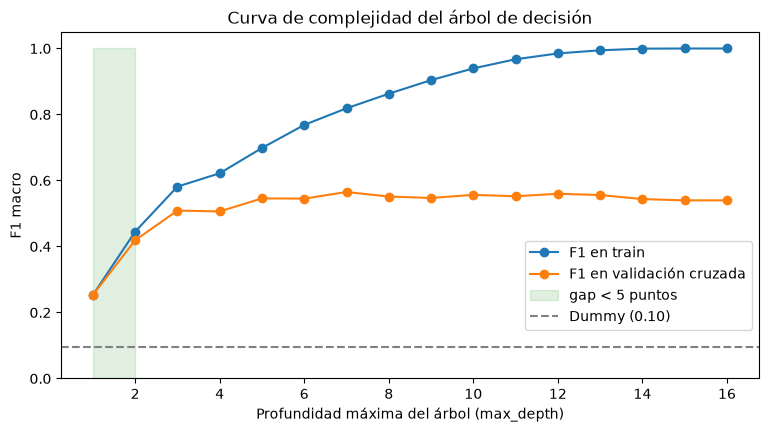

,profundidad,F1 train,F1 CV,nivel F1,gap (puntos),nivel gap
0,1,0.253,0.253,❌ malo,-0.006,✅ correcto
1,2,0.445,0.419,⚠️ flojo,2.604,✅ correcto
2,3,0.581,0.509,✅ aceptable,7.263,⚠️ ligero sobreajuste
3,4,0.622,0.506,✅ aceptable,11.563,❌ sobreajuste grave
4,5,0.699,0.546,✅ aceptable,15.274,❌ sobreajuste grave
5,6,0.768,0.545,✅ aceptable,22.335,❌ sobreajuste grave
6,7,0.819,0.565,✅ aceptable,25.357,❌ sobreajuste grave
7,8,0.863,0.551,✅ aceptable,31.157,❌ sobreajuste grave


In [7]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import validation_curve

profundidades = np.arange(1, 17)
f1_train, f1_cv = validation_curve(
    arbol_libre, X_train, y_train,
    param_name="arbol__max_depth", param_range=profundidades,
    cv=cv, scoring="f1_macro",
)
media_train, media_cv = f1_train.mean(axis=1), f1_cv.mean(axis=1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(profundidades, media_train, marker="o", label="F1 en train")
ax.plot(profundidades, media_cv, marker="o", label="F1 en validación cruzada")
ax.fill_between(profundidades, 0, 1, where=(media_train - media_cv) < 0.05,
                alpha=0.12, color="green", label="gap < 5 puntos")
ax.axhline(F1_DUMMY, linestyle="--", color="grey", label=f"Dummy ({F1_DUMMY:.2f})")
ax.set(xlabel="Profundidad máxima del árbol (max_depth)", ylabel="F1 macro",
       title="Curva de complejidad del árbol de decisión", ylim=(0, 1.05))
ax.legend(loc="lower right", bbox_to_anchor=(1, 0.12))
plt.show()

curva = pd.DataFrame({
    "profundidad": profundidades,
    "F1 train": media_train,
    "F1 CV": media_cv,
    "nivel F1": [nivel_f1(f) for f in media_cv],
    "gap (puntos)": 100 * (media_train - media_cv),
    "nivel gap": [nivel_gap(g) for g in media_train - media_cv],
})
curva.round(3).head(8)

**Qué vemos:** la línea de CV sube hasta la profundidad 5–7 (alrededor de 0.55) y después se queda plana, entre 0.54 y 0.57. En cambio, la de train sigue subiendo hasta 1.00. A partir de ahí, **más profundidad no mejora la validación: solo añade memoria**. Limitando solo la profundidad, el gap baja de 5 puntos únicamente con árboles de 1 o 2 niveles, que se quedan cortos (F1 en CV de 0.25 y 0.42).

Limitar la profundidad es una forma de frenar el árbol, pero no la única. En el paso 7 probamos también un **mínimo de parcelas por hoja** (`min_samples_leaf`): una hoja no se crea si no la respaldan suficientes parcelas, lo que evita las reglas a medida de 2 o 3 casos.

### 6.3 ¿Y si el árbol tuviera que predecir un sitio nuevo?

**Qué hacemos:** repetimos la validación cruzada con `StratifiedGroupKFold`, que pone **todas las parcelas de un mismo sitio en el mismo trozo**. Así, cuando se mide un trozo, el árbol no ha visto nunca ese sitio.

**Por qué:** el EDA mostró que el sitio marca mucho la clase. Con la validación normal, parcelas del mismo sitio caen en train y en el trozo de medida, y el árbol puede apoyarse en el sitio. El ADR-0002 acordó medir los dos casos: la validación normal para comparar modelos y la agrupada como comprobación.

**Cómo leer el resultado:** cuanto más baje el F1 respecto a la validación normal, más depende el modelo de conocer el sitio.

In [8]:
from sklearn.model_selection import StratifiedGroupKFold

cv_por_sitio = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
sitios = X_train["Abbrev"]

resultados.append(resumen_cv("Árbol sin límites, por sitio", arbol_libre,
                             cv_usado=cv_por_sitio, grupos=sitios))
mostrar(resultados)

REQUISITOS


,F1 train,F1 CV,nivel F1,gap (puntos),nivel gap,supera baseline (puntos),nivel baseline
modelo,,,,,,,
Dummy (siempre 'good'),0.097,0.097,❌ malo,-0.000,✅ correcto,0.000,❌ no supera
Árbol sin límites,1.000,0.540,✅ aceptable,46.018,❌ sobreajuste grave,44.289,✅ supera claramente
"Árbol sin límites, por sitio",1.000,0.403,⚠️ flojo,59.675,❌ sobreajuste grave,30.632,✅ supera claramente


MÉTRICAS (validación cruzada)


,accuracy,accuracy balanceada,precision macro,recall macro,F1 macro,F1 macro (desv.),F1 ponderado
modelo,,,,,,,
Dummy (siempre 'good'),0.320,0.200,0.064,0.200,0.097,0.000,0.155
Árbol sin límites,0.539,0.543,0.543,0.543,0.540,0.020,0.539
"Árbol sin límites, por sitio",0.431,0.415,0.440,0.415,0.403,0.052,0.421


**Qué vemos:** con sitios nunca vistos, el F1 cae de **0.54 a 0.40**, y la variación entre trozos se dispara (de ±0.02 a ±0.05). El árbol se apoya bastante en "de qué sitio es la parcela". Si la app se usa con parcelas de sitios nuevos, hay que esperar un rendimiento más cercano a 0.40 que a 0.54. Lo dejaremos escrito en la conclusión.

### Desbalance de clases

La guía propone, de más simple a más complejo: `class_weight="balanced"`, cambiar el umbral o remuestrear. Probamos la opción más simple dentro del paso 7. `class_weight="balanced"` hace que un error en una clase pequeña (`best`, `low`) pese más que uno en `good`.

### Preguntas de la guía (paso 6)
- **¿La diferencia entre modelos es real o está dentro del ruido de la validación cruzada?** Usamos la desviación entre los 5 trozos: diferencias menores de unos 0.02–0.03 puntos de F1 no son concluyentes.
- **¿Hay sobreajuste?** Sí, mucho: el árbol sin límites tiene un gap de 46 puntos.
- **¿Hay subajuste?** Con profundidad 1–2, sí: train y CV son bajos a la vez.
- **¿Necesito un modelo explicable?** El árbol es el modelo más explicable de los cuatro del equipo: se puede dibujar y leer como reglas *si… entonces…* (paso 9).

## Paso 7: ajuste de hiperparámetros (tuning)

**Qué hacemos:** con `GridSearchCV` probamos **120 combinaciones** de 4 hiperparámetros y medimos cada una con la misma validación cruzada.

| Hiperparámetro | Qué controla | Valores |
|---|---|---|
| `criterion` | Cómo mide el árbol lo "mezcladas" que quedan las clases tras una pregunta | `gini`, `entropy` |
| `max_depth` | Número máximo de preguntas encadenadas | 2, 3, 4, 5, 7, sin límite |
| `min_samples_leaf` | Mínimo de parcelas en cada hoja | 1, 5, 10, 20, 30 |
| `class_weight` | Si las clases pequeñas pesan más | ninguno, `balanced` |

La rejilla parte de la del ejemplo del workshop (`Pokemon_Legendary.ipynb`) y la amplía con `min_samples_leaf` y más profundidades.

**Por qué no basta con "la mejor nota":** por defecto, `GridSearchCV` se queda con la combinación de mayor F1 en CV, sin mirar el sobreajuste. Por eso le damos nuestra propia **regla de elección** (`refit`):
1. Descartar las combinaciones con un **gap mayor de 5 puntos** entre train y CV.
2. De las que quedan, quedarse con la de **mayor F1 en CV**.
3. Si hay empate, la **más simple**: menos profundidad y hojas más grandes.

**Cómo leer el resultado:** primero vemos qué habría elegido `GridSearchCV` "a ciegas" y después lo que elige nuestra regla.

In [9]:
from sklearn.model_selection import GridSearchCV

rejilla = {
    "arbol__criterion": ["gini", "entropy"],
    "arbol__max_depth": [2, 3, 4, 5, 7, None],
    "arbol__min_samples_leaf": [1, 5, 10, 20, 30],
    "arbol__class_weight": [None, "balanced"],
}

def tabla_resultados(cv_results):
    r = pd.DataFrame(cv_results)
    r["gap"] = r["mean_train_score"] - r["mean_test_score"]
    r["profundidad"] = r["param_arbol__max_depth"].fillna(np.inf).astype(float)
    return r

def elegir_sin_sobreajuste(cv_results):
    # Regla de elección: mayor F1 en CV entre las que tienen |gap| < 5 puntos;
    # en caso de empate, el árbol más simple.
    r = tabla_resultados(cv_results)
    candidatos = r[r["gap"].abs() < GAP_MAXIMO]
    candidatos = candidatos.sort_values(
        ["mean_test_score", "profundidad", "param_arbol__min_samples_leaf"],
        ascending=[False, True, False],
    )
    return candidatos.index[0]

busqueda = GridSearchCV(
    arbol_libre, rejilla, cv=cv, scoring="f1_macro",
    return_train_score=True, refit=elegir_sin_sobreajuste, n_jobs=-1,
)
busqueda.fit(X_train, y_train)

tabla = tabla_resultados(busqueda.cv_results_)
# Columnas legibles: un hiperparámetro por columna y las notas con nombres claros
legible = pd.DataFrame({
    "criterion": tabla["param_arbol__criterion"],
    "max_depth": tabla["param_arbol__max_depth"].fillna("sin límite"),
    "min_samples_leaf": tabla["param_arbol__min_samples_leaf"],
    "class_weight": tabla["param_arbol__class_weight"].fillna("ninguno"),
    "F1 train": tabla["mean_train_score"].round(3),
    "F1 CV": tabla["mean_test_score"].round(3),
    "F1 CV (desv.)": tabla["std_test_score"].round(3),
    "nivel F1": tabla["mean_test_score"].map(nivel_f1),
    "gap (puntos)": (100 * tabla["gap"]).round(1),
    "nivel gap": tabla["gap"].map(nivel_gap),
})
a_ciegas = legible.loc[tabla["rank_test_score"].idxmin()]
elegida = legible.loc[busqueda.best_index_]
pd.DataFrame({"a ciegas (mayor F1)": a_ciegas, "nuestra regla": elegida})

,a ciegas (mayor F1),nuestra regla
criterion,entropy,entropy
max_depth,sin límite,4
min_samples_leaf,1,30
class_weight,ninguno,ninguno
F1 train,1.0,0.595
F1 CV,0.566,0.565
F1 CV (desv.),0.026,0.025
nivel F1,✅ aceptable,✅ aceptable
gap (puntos),43.4,3.0
nivel gap,❌ sobreajuste grave,✅ correcto


**Qué vemos:**
- **A ciegas**, `GridSearchCV` elegiría un árbol **sin límites** (`entropy`, sin profundidad máxima, hojas de 1 parcela). Tiene el mayor F1 en CV (0.566), pero acierta el 100 % de train: **gap de 43 puntos**. Incumple la regla del proyecto.
- **Nuestra regla** elige `entropy`, profundidad 4 y **30 parcelas por hoja como mínimo**. Su F1 en CV es **prácticamente el mismo (0.565)**, pero con un gap de solo **3 puntos**.

Es la lección principal de este notebook: **la combinación con la nota más alta no tiene por qué ser la mejor**. Un árbol con hojas grandes aprende lo mismo que uno que memoriza, pero generaliza.

Veamos las 5 mejores combinaciones que cumplen la regla. Varias son el **mismo árbol**: con 30 parcelas por hoja, el árbol ya no puede pasar de profundidad 4, y poner `max_depth` = 5, 7 o sin límite no cambia nada. Por eso, en caso de empate, la regla elige la menor profundidad.

In [10]:
cumple = tabla["gap"].abs() < GAP_MAXIMO
print(f"Combinaciones que cumplen gap < 5 puntos: {cumple.sum()} de {len(tabla)}")
legible[cumple].sort_values("F1 CV", ascending=False).head(5)

Combinaciones que cumplen gap < 5 puntos: 42 de 120


,criterion,max_depth,min_samples_leaf,class_weight,F1 train,F1 CV,F1 CV (desv.),nivel F1,gap (puntos),nivel gap
59,entropy,sin límite,30,ninguno,0.595,0.565,0.025,✅ aceptable,3.0,✅ correcto
44,entropy,4,30,ninguno,0.595,0.565,0.025,✅ aceptable,3.0,✅ correcto
54,entropy,7,30,ninguno,0.595,0.565,0.025,✅ aceptable,3.0,✅ correcto
49,entropy,5,30,ninguno,0.595,0.565,0.025,✅ aceptable,3.0,✅ correcto
114,entropy,7,30,balanced,0.601,0.561,0.049,✅ aceptable,3.9,✅ correcto


### El árbol elegido, frente a los anteriores

**Qué hacemos:** añadimos el árbol elegido a la tabla de resultados, con la validación normal y con la validación por sitio.

**Cómo leer el resultado:** el árbol elegido debe tener un F1 en CV parecido al del árbol sin límites, pero un gap menor de 5 puntos.

In [11]:
mejor_arbol = busqueda.best_estimator_
print("Hiperparámetros elegidos:", {k.replace("arbol__", ""): v
                                    for k, v in busqueda.best_params_.items()})
print("Profundidad:", mejor_arbol["arbol"].get_depth(),
      "| hojas:", mejor_arbol["arbol"].get_n_leaves())

resultados.append(resumen_cv("Árbol elegido", mejor_arbol))
resultados.append(resumen_cv("Árbol elegido, por sitio", mejor_arbol,
                             cv_usado=cv_por_sitio, grupos=sitios))
mostrar(resultados)

Hiperparámetros elegidos: {'class_weight': None, 'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 30}
Profundidad: 4 | hojas: 10
REQUISITOS


,F1 train,F1 CV,nivel F1,gap (puntos),nivel gap,supera baseline (puntos),nivel baseline
modelo,,,,,,,
Dummy (siempre 'good'),0.097,0.097,❌ malo,-0.000,✅ correcto,0.000,❌ no supera
Árbol sin límites,1.000,0.540,✅ aceptable,46.018,❌ sobreajuste grave,44.289,✅ supera claramente
"Árbol sin límites, por sitio",1.000,0.403,⚠️ flojo,59.675,❌ sobreajuste grave,30.632,✅ supera claramente
Árbol elegido,0.595,0.565,✅ aceptable,3.001,✅ correcto,46.818,✅ supera claramente
"Árbol elegido, por sitio",0.584,0.519,✅ aceptable,6.570,⚠️ ligero sobreajuste,42.165,✅ supera claramente


MÉTRICAS (validación cruzada)


,accuracy,accuracy balanceada,precision macro,recall macro,F1 macro,F1 macro (desv.),F1 ponderado
modelo,,,,,,,
Dummy (siempre 'good'),0.320,0.200,0.064,0.200,0.097,0.000,0.155
Árbol sin límites,0.539,0.543,0.543,0.543,0.540,0.020,0.539
"Árbol sin límites, por sitio",0.431,0.415,0.440,0.415,0.403,0.052,0.421
Árbol elegido,0.582,0.559,0.633,0.559,0.565,0.025,0.576
"Árbol elegido, por sitio",0.537,0.535,0.547,0.535,0.519,0.110,0.530


**Qué vemos en la tabla de requisitos:**

| | F1 CV | nivel gap | supera baseline |
|---|---|---|---|
| Árbol sin límites | 0.540 ✅ aceptable | ❌ sobreajuste grave (46) | ✅ +44 puntos |
| **Árbol elegido** | **0.565 ✅ aceptable** | **✅ correcto (3.0)** | **✅ +47 puntos** |

- El árbol elegido tiene **4 niveles y 10 hojas**, frente a los 16 niveles y 139 hojas del árbol sin límites. Es el único modelo hasta ahora que **cumple todos los requisitos** en la validación normal.
- **Por sitio**, el árbol elegido mejora mucho al árbol sin límites (0.52 frente a 0.40), porque con hojas de 30 parcelas no puede hacer reglas para 2 o 3 parcelas de un sitio concreto. Aun así sale ⚠️ *ligero sobreajuste* (6.6 puntos) y varía mucho entre repartos (±0.11). La regla de los 5 puntos se aplica a la validación normal (`docs/acuerdos.md`), pero lo anotamos como límite del modelo para sitios nuevos.

**Qué vemos en la tabla de métricas:** la **precision macro (0.63)** es más alta que el **recall macro (0.56)**: cuando el árbol dice "esta parcela es X", suele acertar, pero se le escapan parcelas de algunas clases. En el paso 8 veremos en la matriz de confusión cuáles. El F1 ponderado (0.58) es parecido al macro (0.565), así que el árbol no está descuidando las clases pequeñas en general.

### Preguntas de la guía (paso 7)
- **¿Vale la pena el tiempo?** Aquí sí. El tuning no sube mucho el F1, pero **elimina el sobreajuste**, y sin eso el modelo no cumpliría el proyecto.
- **¿Estoy sobreajustando a la validación de tanto probar combinaciones?** Es un riesgo real con 120 combinaciones. Lo controlamos de tres formas: cada combinación se mide con validación cruzada (5 repartos, no uno), la regla prefiere el árbol más simple en los empates, y `data/val.csv` no se ha usado para elegir. En el paso 8 lo comprobaremos: si el F1 en `val.csv` sale parecido al de la CV, no hemos sobreajustado la elección.

## Paso 8: evaluación con `val.csv`

**Qué hacemos:** por primera vez usamos `data/val.csv`, 110 parcelas que el árbol no ha visto nunca. El árbol elegido en el paso 7 ya está entrenado con todo `train.csv` (lo hace `GridSearchCV` al terminar). Ahora:
1. Predecimos la clase de cada parcela de validación.
2. A las **parcelas sin medidas** les ponemos `none` por regla, sin hacer caso al árbol (ADR-0001).
3. Calculamos los requisitos y las métricas dos veces: con **toda la validación** y **solo con las parcelas con medidas**.

**Por qué en validación y no en test (desviación consciente de la guía):** la guía hace la evaluación final en el test. En nuestro proyecto hay 4 modelos y el test solo puede usarse **una vez**, con el ganador, en `06_conclusiones`. Por eso cada modelo se evalúa aquí con `val.csv`, y esa nota es la que sirve para elegir al ganador (`docs/acuerdos.md`).

**Por qué dos veces:** 15 de las 110 parcelas de validación no tienen medidas y la regla las acierta todas, con cualquier modelo. Con toda la validación vemos lo que vería la app; solo con las parcelas con medidas vemos lo que **aporta de verdad el árbol**.

**Cómo leer el resultado:** las mismas dos tablas de antes, pero ahora con `val.csv`. Para que la comparación sea justa, el baseline es **el Dummy con la misma regla**.

In [12]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

X_val = val.drop(columns=OBJETIVO)
y_val = val[OBJETIVO]
con_medidas = ~sin_medidas(X_val)  # True en las 95 parcelas con medidas

def predecir_con_regla(modelo, X):
    # Predice con el modelo y pone "none" a las parcelas sin medidas (ADR-0001)
    prediccion = pd.Series(modelo.predict(X), index=X.index)
    prediccion[sin_medidas(X)] = "none"
    return prediccion

# El Dummy se entrena igual, con train, para tener un baseline justo
dummy.fit(X_train, y_train)
pred_dummy = predecir_con_regla(dummy, X_val)
pred_arbol = predecir_con_regla(mejor_arbol, X_val)

# F1 en train del árbol final (entrenado con las 469 parcelas), para el gap
F1_TRAIN_ARBOL = f1_score(y_train, mejor_arbol.predict(X_train), average="macro")
print(f"Parcelas de validación: {len(y_val)} "
      f"({con_medidas.sum()} con medidas y {(~con_medidas).sum()} sin medidas)")
print(f"F1 macro del árbol final en train: {F1_TRAIN_ARBOL:.3f}")

Parcelas de validación: 110 (95 con medidas y 15 sin medidas)
F1 macro del árbol final en train: 0.557


In [13]:
def resumen_val(nombre, y_real, y_pred, f1_base, f1_train=None):
    # Misma idea que resumen_cv, pero con unas predicciones ya hechas
    f1 = f1_score(y_real, y_pred, average="macro")
    puntos = 100 * (f1 - f1_base)
    gap = None if f1_train is None else f1_train - f1
    return {
        "modelo": nombre,
        "F1 train": f1_train,
        "F1 val": f1,
        "nivel F1": nivel_f1(f1),
        "gap (puntos)": None if gap is None else 100 * gap,
        "nivel gap": "—" if gap is None else nivel_gap(gap),
        "supera baseline (puntos)": puntos,
        "nivel baseline": nivel_baseline(puntos),
        "accuracy": accuracy_score(y_real, y_pred),
        "accuracy balanceada": balanced_accuracy_score(y_real, y_pred),
        "precision macro": precision_score(y_real, y_pred, average="macro",
                                           zero_division=0),
        "recall macro": recall_score(y_real, y_pred, average="macro", zero_division=0),
        "F1 macro": f1,
        "F1 ponderado": f1_score(y_real, y_pred, average="weighted"),
    }

ym, dm, am = y_val[con_medidas], pred_dummy[con_medidas], pred_arbol[con_medidas]
f1_dummy_todas = f1_score(y_val, pred_dummy, average="macro")
f1_dummy_medidas = f1_score(ym, dm, average="macro")

evaluacion = [
    resumen_val("Toda la validación: Dummy + regla", y_val, pred_dummy, f1_dummy_todas),
    resumen_val("Toda la validación: árbol + regla", y_val, pred_arbol, f1_dummy_todas),
    resumen_val("Con medidas: Dummy", ym, dm, f1_dummy_medidas),
    resumen_val("Con medidas: árbol", ym, am, f1_dummy_medidas, F1_TRAIN_ARBOL),
]
df_val = pd.DataFrame(evaluacion).set_index("modelo")
print("REQUISITOS (validación)")
display(df_val[["F1 train", "F1 val", "nivel F1", "gap (puntos)", "nivel gap",
                "supera baseline (puntos)", "nivel baseline"]].round(3))
print("MÉTRICAS (validación)")
display(df_val[["accuracy", "accuracy balanceada", "precision macro",
                "recall macro", "F1 macro", "F1 ponderado"]].round(3))

REQUISITOS (validación)


,F1 train,F1 val,nivel F1,gap (puntos),nivel gap,supera baseline (puntos),nivel baseline
modelo,,,,,,,
Toda la validación: Dummy + regla,NaN,0.244,❌ malo,NaN,—,0.000,❌ no supera
Toda la validación: árbol + regla,NaN,0.562,✅ aceptable,NaN,—,31.804,✅ supera claramente
Con medidas: Dummy,NaN,0.101,❌ malo,NaN,—,0.000,❌ no supera
Con medidas: árbol,0.557,0.520,✅ aceptable,3.611,✅ correcto,41.969,✅ supera claramente


MÉTRICAS (validación)


,accuracy,accuracy balanceada,precision macro,recall macro,F1 macro,F1 ponderado
modelo,,,,,,
Toda la validación: Dummy + regla,0.427,0.311,0.267,0.311,0.244,0.322
Toda la validación: árbol + regla,0.636,0.565,0.661,0.565,0.562,0.608
Con medidas: Dummy,0.337,0.200,0.067,0.200,0.101,0.170
Con medidas: árbol,0.579,0.528,0.617,0.528,0.520,0.548


**Qué vemos en la tabla de requisitos:**

| | F1 val | gap | supera baseline |
|---|---|---|---|
| Toda la validación: árbol + regla | 0.562 ✅ aceptable | — | ✅ +32 puntos sobre el Dummy + regla |
| **Con medidas: árbol** | **0.520 ✅ aceptable** | **✅ correcto (3.6)** | **✅ +42 puntos** |

- **El gap se mide donde trabaja el árbol** (decisión del equipo): F1 en train 0.557 frente a 0.520 en las parcelas de validación con medidas, **3.6 puntos**. ✅ Cumple el requisito de overfitting.
- **La regla ayuda a todos por igual:** el Dummy pasa de 0.10 a 0.24 de F1 solo por acertar las 15 parcelas sin medidas. Por eso el baseline justo es el Dummy *con* la regla.
- **Con medidas, el árbol baja de 0.56 a 0.52:** las 15 parcelas sin medidas eran aciertos "gratis". 0.52 es la nota real del árbol.

**Qué vemos en la tabla de métricas:** como en la validación cruzada, la **precision macro (0.62) es mayor que el recall macro (0.53)**. El árbol es "prudente": acierta cuando se decide por una clase, pero no encuentra muchas parcelas de algunas clases. Lo vemos clase a clase a continuación.

### Métricas por clase

**Qué hacemos:** sacamos precision, recall y F1 de **cada una de las 5 clases**, como pide el enunciado (*"Precision, Recall y F1 por clase"*).

**Cómo leer el resultado:** para cada clase,
- **precision**: de las parcelas que el árbol dice que son de esa clase, qué parte lo es de verdad;
- **recall**: de las parcelas que son de esa clase, qué parte encuentra el árbol;
- **soporte**: cuántas parcelas de esa clase hay en validación.

In [14]:
from sklearn.metrics import classification_report


def por_clase(y_real, y_pred):
    informe = classification_report(y_real, y_pred, labels=ORDEN_CLASES,
                                    output_dict=True, zero_division=0)
    return pd.DataFrame(informe).T.loc[ORDEN_CLASES].rename(
        columns={"f1-score": "f1", "support": "soporte"})

pd.concat({"toda la validación (árbol + regla)": por_clase(y_val, pred_arbol),
           "solo con medidas (árbol)": por_clase(ym, am)}, axis=1).round(2)

toda la validación (árbol + regla)                       \
                                 precision recall    f1 soporte   
none                                  0.79   0.85  0.82    27.0   
low                                   0.83   0.31  0.45    16.0   
average                               0.48   0.63  0.55    19.0   
good                                  0.60   0.84  0.70    32.0   
best                                  0.60   0.19  0.29    16.0   

        solo con medidas (árbol)                       
                       precision recall    f1 soporte  
none                        0.57   0.67  0.62    12.0  
low                         0.83   0.31  0.45    16.0  
average                     0.48   0.63  0.55    19.0  
good                        0.60   0.84  0.70    32.0  
best                        0.60   0.19  0.29    16.0

**Qué vemos:**
- **`good` (F1 0.70) y `none` (0.82 con la regla, 0.62 solo con medidas)** son las clases que mejor reconoce. `good` es la más numerosa en train y `none` tiene la ayuda de la regla.
- **`best` es el gran problema: recall de 0.19.** De 16 parcelas `best`, solo encuentra 3. Cuando dice `best` acierta (precision 0.60), pero casi nunca se atreve a decirlo.
- **`low` tiene un patrón parecido:** precision alta (0.83), recall bajo (0.31).
- **`average`** queda en medio (F1 0.55).

Fuera de `none`, las filas de las dos columnas son iguales: la regla solo cambia las parcelas `none` sin medidas.

### Matriz de confusión

**Qué hacemos:** contamos, para cada clase real (filas), en qué clase la ha puesto el árbol (columnas).

**Cómo leer el gráfico:**
- La **diagonal** son los aciertos.
- Cada casilla fuera de la diagonal es un tipo de error: fila = lo que era, columna = lo que dijo el árbol.
- Las clases van ordenadas de peor a mejor (`none` → `best`), así que **un error lejos de la diagonal es más grave** (por ejemplo, `best` predicho como `none`).

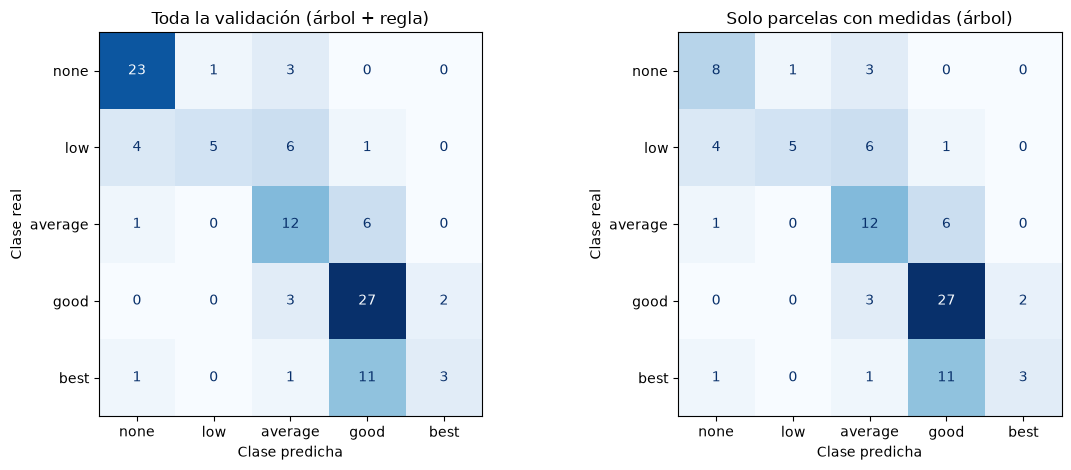

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for eje, (titulo, y_r, y_p) in zip(ejes, [
    ("Toda la validación (árbol + regla)", y_val, pred_arbol),
    ("Solo parcelas con medidas (árbol)", ym, am),
]):
    ConfusionMatrixDisplay.from_predictions(
        y_r, y_p, labels=ORDEN_CLASES, ax=eje, colorbar=False, cmap="Blues")
    eje.set(title=titulo, xlabel="Clase predicha", ylabel="Clase real")
plt.tight_layout()
plt.show()

**Qué vemos:**
- **El error más frecuente: `best` predicho como `good` (11 de 16 parcelas `best`).** El árbol no consigue separar "muy buena" de "buena". Es un error entre clases **vecinas**, el menos grave.
- **`low` se reparte entre `average` (6) y `none` (4):** tampoco lo separa bien de sus vecinas.
- **Errores lejos de la diagonal** (a 2 o más clases de distancia) hay 7: 3 `none` predichas como `average`, 1 `low` como `good`, 1 `average` como `none`, 1 `best` como `average` y 1 `best` como `none` (el más grave). **33 de los 40 errores son entre clases vecinas** en la escala.
- La única diferencia entre las dos matrices es la casilla `none`/`none`: 23 con la regla y 8 sin ella. Las 15 de la regla son siempre aciertos.

En el paso 9 miraremos esas parcelas mal clasificadas para entender **por qué** se equivoca.

### ¿Rinde igual en todos los sitios? (subgrupos)

**Qué hacemos:** calculamos el % de aciertos de la validación en cada sitio.

**Por qué:** la guía pregunta *"¿Rinde igual en todos los subgrupos?"*. Nuestro subgrupo natural es el sitio.

**Cómo leer el resultado:** con pocas parcelas por sitio (algunos solo tienen 1 o 2 en validación), las diferencias pequeñas no significan nada. Fíjate solo en los extremos.

In [16]:
aciertos = pd.DataFrame({"sitio": X_val["Abbrev"], "acierto": y_val == pred_arbol,
                         "sin medidas": ~con_medidas})
por_sitio = aciertos.groupby("sitio").agg(
    parcelas=("acierto", "size"), aciertos=("acierto", "sum"),
    sin_medidas=("sin medidas", "sum"), pct_acierto=("acierto", "mean"),
).sort_values("pct_acierto")
print("Sitios de validación que no están en train:",
      sorted(set(X_val["Abbrev"]) - set(X_train["Abbrev"])))
print("Especies de validación que no están en train:",
      sorted(set(X_val["Sp"]) - set(X_train["Sp"])))
por_sitio.round(2)

Sitios de validación que no están en train: ['Mor', 'Wen']
Especies de validación que no están en train: ['ra', 'te']


,parcelas,aciertos,sin_medidas,pct_acierto
sitio,,,,
Cly,2,0,0,0.00
Nga,1,0,0,0.00
WSh,1,0,0,0.00
Cra,6,2,0,0.33
K82,5,2,0,0.40
K81,13,6,0,0.46
K83,8,4,0,0.50
Wak,8,4,0,0.50
K81a,6,4,0,0.67


**Qué vemos:**
- Los sitios **Mor** y **Wen** no aparecen en train: todas sus parcelas son sin medidas (se quitaron de train, ADR-0001), así que en validación las resuelve la regla.
- Hay **2 especies que el árbol no ha visto nunca** (`ra` y `te`). El `OrdinalEncoder` les da el valor −1 y el árbol no falla: esto es justo lo que preparamos con `handle_unknown` en el paso 3.
- El acierto varía mucho de un sitio a otro, pero la mayoría de sitios tienen menos de 10 parcelas en validación, demasiado pocas para sacar conclusiones por sitio. La comprobación seria por sitio es la del paso 6.3 (`StratifiedGroupKFold`).

### Preguntas de la guía (paso 8)
- **¿La métrica coincide con la definida en el paso 0?** Sí: F1 macro, con accuracy y métricas por clase al lado.
- **¿Rinde igual en todos los subgrupos?** No del todo: rinde peor con sitios nuevos (paso 6.3) y en las clases `best` y `low`. Por sitio, en validación hay demasiado pocas parcelas para concluir nada.
- **¿El resultado es parecido al de validación (aquí: al de la validación cruzada)?** Sí. F1 0.565 en CV y 0.562 en `val.csv` con la regla: **no hemos sobreajustado la elección de hiperparámetros** (la duda que dejamos abierta en el paso 7). El test se usará en `06_conclusiones`.
- **Calibración y umbral:** la guía sugiere no dejar el umbral por defecto. Con 5 clases y un modelo que no destaca por sus probabilidades (un árbol con 10 hojas solo da 10 valores de probabilidad distintos), no lo ajustamos. Lo dejamos como mejora posible para `best`.